# Bước 6B — Pilot train B1/B2 có đối chứng và kiểm checkpoint
**Đồ án CV nâng cao · Nhóm A/B/C · 05/11/2026**

Notebook chạy train thật trên subset **128 identity**, không phải toàn bộ thí nghiệm cuối. Câu hỏi chính: dữ liệu/augmentation có đúng không, encoder có học không, B1/B2 có cùng ngân sách không, checkpoint có nạp/tiếp tục được không và máy cần bao nhiêu thời gian/VRAM?

B1 = dữ liệu nền DigiFace; B2 = cùng nền với 50% lượt ảnh thêm che. Warm-up classifier một epoch, rồi mở block cuối và projection hai epoch. Classifier chỉ dùng huấn luyện trên 128 người; khi đánh giá **200 người mới validation**, bỏ classifier, dùng embedding 512 chiều và evaluator 1:N.

Kết quả có thể không cải thiện B0; phải giữ cả suy giảm và phân tích giới hạn. Test/ROF/MFR2 không dùng trong notebook này.

## 1. Cấu hình đã định trước và môi trường

Giữ batch=32, AdamW, LR classifier 1e-3, LR encoder 3e-5, weight decay 1e-4, clip gradient 5. B1/B2 cùng initialization, image order, RNG dropout mỗi bước, lịch validation và tổng optimizer steps. Không early-stop một nhánh sớm để làm lệch ngân sách; checkpoint tốt nhất được chọn trong hai epoch fine-tune đã hoàn thành.

Checkpoint chọn theo DIR validation nền tại FPIR ≤5%, tie-break bằng DIR query che ở cùng threshold, rồi epoch sớm hơn. Threshold mỗi model chỉ chọn bằng validation nền; panel che giữ đúng threshold đó để đo robustness. Chưa chọn cấu hình theo test.

In [1]:
from __future__ import annotations
from pathlib import Path
from datetime import datetime,timezone
from concurrent.futures import ThreadPoolExecutor
import os,json,hashlib,time,math,copy,platform,gc,importlib.metadata
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG',':4096:8')
for name in ['OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS']:os.environ[name]='4'
import numpy as np
import pandas as pd
from PIL import Image,ImageOps
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
import torch
from torch import nn
import torch.nn.functional as F
from facenet_pytorch import InceptionResnetV1
from facenet_pytorch.models.mtcnn import fixed_image_standardization

def find_root():
    choices=[Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    choices += [Path.cwd(),*Path.cwd().parents]
    for p in choices:
        if (p/'ban_giao_nhom/huan_luyen/Pilot_train_B1_B2.ipynb').is_file():return p.resolve()
    raise FileNotFoundError('Mở bản tiếp nối bước6 hoặc đặt CV_PROJECT_ROOT')
ROOT=find_root();HERE=ROOT/'ban_giao_nhom/huan_luyen';OUT=HERE/'notebook_outputs'
TAB,FIG,CACHE,CKPT=OUT/'tables',OUT/'figures',OUT/'cache',HERE/'checkpoints'
for p in [OUT,TAB,FIG,CACHE,CKPT]:p.mkdir(parents=True,exist_ok=True)
START=time.perf_counter();torch.set_num_threads(4)
torch.backends.cudnn.benchmark=False;torch.backends.cudnn.deterministic=True
torch.backends.cuda.matmul.allow_tf32=False;torch.backends.cudnn.allow_tf32=True
DEVICE='cuda:0' if torch.cuda.is_available() else 'cpu'
assert DEVICE.startswith('cuda'),'Pilot tài nguyên này yêu cầu GPU đã có; không tự chuyển thành lượt CPU rất dài'

def sha(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(2**20),b''):h.update(b)
    return h.hexdigest()
def digest(x):return hashlib.sha256(json.dumps(x,sort_keys=True,ensure_ascii=False,default=str).encode()).hexdigest()
def save(d,name):d.to_csv(TAB/(name+'.csv'),index=False,encoding='utf-8-sig',float_format='%.17g');return d
def jwrite(x,name):(OUT/name).write_text(json.dumps(x,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
def state_sha(state):
    h=hashlib.sha256()
    for k,t in sorted(state.items()):h.update(k.encode());h.update(t.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()
def vn(x,d=0):return f'{x:,.{d}f}'.replace(',','_').replace('.',',').replace('_','.')
def finish(fig,name):
    for ext in ['png','svg']:fig.savefig(FIG/(name+'.'+ext),bbox_inches='tight',dpi=160)
    display(fig);plt.close(fig)
plt.rcParams.update({'font.family':'Arial','figure.dpi':110,'axes.unicode_minus':False})

ADIR=ROOT/'ban_giao_nhom/augmentation/notebook_outputs'
CONTRACT=ADIR/'augmentation_pilot_contract.json'
contract=json.loads(CONTRACT.read_text(encoding='utf-8'));AUG=contract['augmentation'];CFG=contract['pilot'];SEED=CFG['seed']
T=pd.read_csv(ADIR/'tables/01_pilot_train.csv',dtype=str,keep_default_na=False)
M=pd.read_csv(ADIR/'tables/01_pilot_monitor.csv',dtype=str,keep_default_na=False)
V=pd.read_csv(ADIR/'tables/01_validation_roles.csv',dtype=str,keep_default_na=False)
TS=pd.read_csv(ADIR/'tables/02_B2_train_variant_specs.csv',dtype={'seed':str})
VS=pd.read_csv(ADIR/'tables/02_validation_query_variant_specs.csv',dtype={'seed':str})
labels=json.loads((ADIR/'label_mapping.json').read_text())
assert sha(ADIR/'tables/02_B2_train_variant_specs.csv')==contract['train_spec_sha256']
assert sha(ADIR/'tables/02_validation_query_variant_specs.csv')==contract['validation_spec_sha256']
assert sha(ADIR/'label_mapping.json')==contract['label_mapping_sha256']
assert set(T.canonical_identity)==set(labels) and len(T)==4608 and len(M)==512 and len(V)==8000
assert not set(T.canonical_identity)&set(V.canonical_identity)
INPUT_HASH={'contract':sha(CONTRACT),'roles':sha(ROOT/'ban_giao_nhom/protocol/notebook_outputs/tables/05_image_roles_draft.csv')}
NB=HERE/'Pilot_train_B1_B2.ipynb'
nb_cells=json.loads(NB.read_text(encoding='utf-8'))['cells']
SOURCE_SHA=digest([(c['cell_type'],''.join(c['source'])) for c in nb_cells])
ENV={'python':platform.python_version(),'torch':str(torch.__version__),'facenet_pytorch':importlib.metadata.version('facenet-pytorch'),
     'numpy':np.__version__,'pandas':pd.__version__,'pillow':Image.__version__,
     'gpu':torch.cuda.get_device_name(0),'device':DEVICE,'vram_total_MiB':torch.cuda.get_device_properties(0).total_memory/2**20,
     'amp':False,'cpu_threads':4,'data_loader_workers':0,'seed':SEED}
display(pd.DataFrame([ENV]).T);display(pd.DataFrame([{'parameter':k,'value':str(v)} for k,v in CFG.items()]))

H:\Nam tu\Hoc Ki 1\CV nang cao\Đồ Án\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,0
python,3.11.9
torch,2.2.2+cu121
facenet_pytorch,2.6.0
numpy,1.26.4
pandas,2.2.3
pillow,10.2.0
gpu,NVIDIA GeForce RTX 4060 Laptop GPU
device,cuda:0
vram_total_MiB,8187.5
amp,False


,parameter,value
0,version,pilot_128ids_v1
1,seed,20261105
2,identities,128
3,batch_size,32
4,head_warmup_epochs,1
5,fine_tune_epochs,2
6,full_training_claimed,False
7,checkpoint_selection,max_base_validation_DIR_at_FPIR05; tie:occlude...
8,encoder_open_layers,"['block8', 'last_linear', 'last_bn']"
9,bn_running_stats,frozen_all_layers


In [2]:
def make_spec(image_id, epoch, partition, force=False):
    seed=int(hashlib.sha256(f"{AUG['seed']}|{partition}|{epoch}|{image_id}".encode()).hexdigest()[:16],16)
    rng=np.random.default_rng(seed)
    applied=bool(force or rng.random()<AUG['train_probability'])
    kind=AUG['kinds'][int(rng.integers(len(AUG['kinds'])))] if applied else 'none'
    box=[0,0,0,0];fill=0
    if applied:
        box=np.array(AUG['boxes'][kind],dtype=int)+rng.integers(-4,5,size=4)
        box=np.clip(box,0,160).tolist()
        fill=int(rng.choice(AUG['fill_values']))
    area=max(0,box[2]-box[0])*max(0,box[3]-box[1])
    return {'image_id':image_id,'epoch':int(epoch),'partition':partition,'seed':str(seed),
            'applied':applied,'kind':kind,'x1':box[0],'y1':box[1],'x2':box[2],'y2':box[3],
            'fill_gray':fill,'mask_pixels':area,'frame_pixels':160*160,
            'mask_fraction_frame':area/(160*160),
            'variant_id':'VAR_'+hashlib.sha256(f'{image_id}|{seed}|{kind}|{box}|{fill}'.encode()).hexdigest()[:24]}

def apply_spec(pixels,spec):
    if pixels.dtype!=np.uint8 or pixels.shape!=(160,160,3):raise ValueError('Expected uint8 RGB160')
    mask=np.zeros((160,160),dtype=np.uint8)
    if bool(spec['applied']):mask[int(spec['y1']):int(spec['y2']),int(spec['x1']):int(spec['x2'])]=1
    if int(mask.sum())!=int(spec['mask_pixels']):raise ValueError('Mask area does not match metadata')
    result=pixels.copy();result[mask.astype(bool)]=int(spec['fill_gray'])
    return result,mask

## 2. Nạp ảnh có cache được kiểm nguồn

Hash **mọi file** train/monitor/validation được dùng, kể cả khi cache khớp. Ảnh chuyển EXIF/RGB/alpha giống B0, resize PIL bilinear160; cache chỉ lưu uint8 RGB, chưa standardize. Dùng memmap để hạn chế RAM; tensor được chuẩn hóa đúng một lần sau augmentation.

Cache pixel có hash bảng, thuật toán, thư viện và bytes file cache; cache không thay bằng chứng lượt train mới. Mọi lượt chạy notebook này đều train mới, không âm thầm đọc log/checkpoint rồi coi là vừa train.

In [3]:
common_src=next(''.join(c['source']) for c in nb_cells if c['cell_type']=='code' and ''.join(c['source']).startswith('def make_spec'))
assert hashlib.sha256(common_src.encode()).hexdigest()==contract['implementation_sha256'],'Mask code khác notebook augmentation'
data=pd.concat([T.assign(cohort='train'),M.assign(cohort='monitor'),V.assign(cohort='val')],ignore_index=True)
assert data.image_id.is_unique
def check_raw(r):return sha(ROOT/r.path)==r.sha256
with ThreadPoolExecutor(max_workers=6) as pool:raw_checks=list(pool.map(check_raw,data.itertuples()))
assert all(raw_checks),'Raw đổi bytes: dừng trước dùng cache/train'
def rgb160(r):
    path=ROOT/r.path
    assert sha(path)==r.sha256
    with Image.open(path) as source:
        im=ImageOps.exif_transpose(source)
        if 'A' in im.getbands():
            rgba=im.convert('RGBA')
            if (np.asarray(rgba.getchannel('A'))<255).any():im=Image.alpha_composite(Image.new('RGBA',rgba.size,(255,255,255,255)),rgba)
        return np.asarray(im.convert('RGB').resize((160,160),Image.Resampling.BILINEAR),dtype=np.uint8).copy()
pixel_fp=digest({'data':data[['image_id','sha256','cohort']].to_csv(index=False),
                 'pipeline':'EXIF_RGBA_white_RGB_PIL_BILINEAR160_v1','pillow':Image.__version__,'source':SOURCE_SHA})
meta_path=CACHE/'pixel_meta.json';cache_ok=False
if meta_path.exists():
    meta=json.loads(meta_path.read_text());cache_ok=meta['fingerprint']==pixel_fp
    if cache_ok:cache_ok=all((CACHE/n).exists() and sha(CACHE/n)==s for n,s in meta['files'].items())
PIX={};pixel_start=time.perf_counter()
if cache_ok:
    PIX={name:np.load(CACHE/(name+'.npy'),mmap_mode='r',allow_pickle=False) for name in ['train','monitor','val']}
    PIXEL_MODE='matching_cache'
else:
    PIXEL_MODE='computed_now'
    for name,frame in [('train',T),('monitor',M),('val',V)]:
        array=np.lib.format.open_memmap(CACHE/(name+'.npy'),mode='w+',dtype=np.uint8,shape=(len(frame),160,160,3))
        records=list(frame.itertuples())
        with ThreadPoolExecutor(max_workers=6) as pool:
            for start in range(0,len(records),256):
                for j,pixels in enumerate(pool.map(rgb160,records[start:start+256])):array[start+j]=pixels
        array.flush();del array
        PIX[name]=np.load(CACHE/(name+'.npy'),mmap_mode='r',allow_pickle=False)
        print(f'Pixel cache {name}: {len(frame)} ảnh',flush=True)
    meta={'fingerprint':pixel_fp,'files':{n+'.npy':sha(CACHE/(n+'.npy')) for n in PIX},'raw_images_hashed':len(data)}
    meta_path.write_text(json.dumps(meta,indent=2),encoding='utf-8')
def tensor_batch(pixels):
    x=torch.from_numpy(np.array(pixels,copy=True)).permute(0,3,1,2).float()
    return fixed_image_standardization(x).to(DEVICE)
base=np.asarray(PIX['train'][:4]);xt=tensor_batch(base).cpu()
expected=(torch.from_numpy(base.copy()).permute(0,3,1,2).float()-127.5)/128
assert torch.equal(xt,expected) and xt.shape==(4,3,160,160) and torch.isfinite(xt).all()
assert not torch.allclose(fixed_image_standardization(xt),expected),'Double-normalization guard not effective'
assert not torch.allclose(fixed_image_standardization(torch.from_numpy(base.copy()).permute(0,3,1,2).float()/255),expected)
display(pd.DataFrame([{'mode':PIXEL_MODE,'raw_images_hashed_now':len(data),'cache_seconds':time.perf_counter()-pixel_start,
                      'uint8_cache_GiB':sum(x.nbytes for x in PIX.values())/2**30}]))

Pixel cache train: 4608 ảnh


Pixel cache monitor: 512 ảnh


Pixel cache val: 8000 ảnh


,mode,raw_images_hashed_now,cache_seconds,uint8_cache_GiB
0,computed_now,13120,8.166763,0.938416


## 3. Model, lớp mở và BatchNorm

Khởi tạo pretrained VGGFace2 rồi thay classifier thành 128 lớp. Warm-up chỉ classifier; fine-tune mở `block8`, `last_linear`, affine của `last_bn`. **Mọi running mean/variance BatchNorm giữ nguyên**; frozen encoder giữ eval, chỉ dropout cuối hoạt động lúc fine-tune.

Đường inference đặt `classify=False`, output phải 512 chiều L2=1, không lấy logits làm embedding. Kiểm gradient encoder ở batch fine-tune và hash phần frozen sau mỗi epoch; warm-up chưa được tính là encoder đã học.

In [4]:
torch.manual_seed(SEED);np.random.seed(SEED)
initial=InceptionResnetV1(pretrained='vggface2',classify=True,num_classes=len(labels))
INITIAL_STATE={k:v.detach().cpu().clone() for k,v in initial.state_dict().items()}
INITIAL_SHA=state_sha(INITIAL_STATE)
FEATURE_INITIAL_SHA=state_sha({k:v for k,v in INITIAL_STATE.items() if not k.startswith('logits.')})
OPEN_PREFIX=tuple(p+'.' for p in CFG['encoder_open_layers'])
def is_open(name):return name.startswith(OPEN_PREFIX)
def create_model():
    model=InceptionResnetV1(pretrained=None,classify=True,num_classes=len(labels))
    model.load_state_dict(INITIAL_STATE,strict=True)
    return model.to(DEVICE)
def mode_train(model,stage):
    model.classify=True;model.eval();model.logits.train()
    for name,p in model.named_parameters():p.requires_grad_(name.startswith('logits.') or (stage=='fine' and is_open(name)))
    if stage=='fine':model.block8.train();model.dropout.train()
    for module in model.modules():
        if isinstance(module,nn.modules.batchnorm._BatchNorm):module.eval()
def make_optimizer(model):
    return torch.optim.AdamW([
        {'params':[p for n,p in model.named_parameters() if n.startswith('logits.')],'lr':CFG['lr_head'],'group_name':'classifier'},
        {'params':[p for n,p in model.named_parameters() if is_open(n)],'lr':CFG['lr_encoder'],'group_name':'encoder'}],weight_decay=CFG['weight_decay'])
def frozen_sha(model):
    return state_sha({k:v for k,v in model.state_dict().items() if not k.startswith('logits.') and not is_open(k)})
def bn_sha(model):return state_sha({k:v for k,v in model.state_dict().items() if any(t in k for t in ['running_mean','running_var','num_batches_tracked'])})
trainable=pd.DataFrame([{'name':n,'parameters':p.numel(),'fine_tune':n.startswith('logits.') or is_open(n),
                         'warmup':n.startswith('logits.')} for n,p in initial.named_parameters()])
save(trainable,'01_parameter_policy')
display(trainable.groupby(['warmup','fine_tune']).parameters.sum().reset_index())
del initial;gc.collect()

,warmup,fine_tune,parameters
0,False,False,20963328
1,False,True,2519296
2,True,True,65664


8

## 4. Warm-up chẩn đoán: classifier có học được một tập rất nhỏ không?

Lấy 16 ảnh/8 người train, trích feature frozen rồi fit một classifier chẩn đoán riêng. Đây là thử label/loss/optimizer trên dữ liệu thật; không phải kết quả nhận diện người mới và không dùng model này khởi tạo B1/B2.

In [5]:
small_idx=[]
for identity in sorted(labels)[:8]:small_idx+=T.index[T.canonical_identity.eq(identity)].tolist()[:2]
debug_model=create_model();debug_model.classify=False;debug_model.eval()
with torch.no_grad():features=debug_model(tensor_batch(PIX['train'][small_idx])).cpu().clone()
debug_y=torch.arange(8).repeat_interleave(2)
head=nn.Linear(512,8);opt_debug=torch.optim.Adam(head.parameters(),lr=.05)
before=float(F.cross_entropy(head(features),debug_y).detach())
for step in range(200):
    opt_debug.zero_grad(set_to_none=True);loss=F.cross_entropy(head(features),debug_y);loss.backward();opt_debug.step()
after=float(F.cross_entropy(head(features),debug_y).detach());accuracy=float((head(features).argmax(1)==debug_y).float().mean())
assert accuracy>=.95 and after<before*.25,'Tiny overfit thất bại: kiểm label/features/optimizer'
save(pd.DataFrame([{'images':16,'identities':8,'loss_before':before,'loss_after':after,'accuracy':accuracy,
                   'used_for_final_initialization':False}]),'02_tiny_overfit_diagnostic')
display(pd.read_csv(TAB/'02_tiny_overfit_diagnostic.csv'))
del debug_model,head,opt_debug,features;gc.collect();torch.cuda.empty_cache()

,images,identities,loss_before,loss_after,accuracy,used_for_final_initialization
0,16,8,2.071484,0.000444,1,False


## 5. Đo batch khả thi và chi phí một bước

Đo batch 16/32/64 trên cấu hình fine-tune bằng model chẩn đoán riêng; warm-up trước timer, đồng bộ CUDA. Không dùng kết quả recognition để chọn batch. Pilot giữ batch32 theo cấu hình nếu vừa VRAM; nếu không vừa phải giảm đồng thời hai nhánh và tạo phiên bản cấu hình mới.

VRAM là peak tensor do PyTorch cấp phát trong tiến trình, không phải toàn bộ bộ nhớ GPU hệ thống. Thời gian còn bị ảnh hưởng bởi ứng dụng dùng chung GPU và chế độ nguồn laptop.

In [6]:
resources=[]
for batch in [16,32,64]:
    probe=create_model();mode_train(probe,'fine');probe_opt=make_optimizer(probe)
    x=tensor_batch(PIX['train'][:batch]);y=torch.tensor([labels[z] for z in T.canonical_identity.iloc[:batch]],device=DEVICE)
    for _ in range(2):
        probe_opt.zero_grad(set_to_none=True);loss=F.cross_entropy(probe(x),y);loss.backward();probe_opt.step()
    torch.cuda.synchronize();torch.cuda.reset_peak_memory_stats();times=[]
    for _ in range(3):
        begin=time.perf_counter();probe_opt.zero_grad(set_to_none=True);loss=F.cross_entropy(probe(x),y);loss.backward()
        nn.utils.clip_grad_norm_([p for p in probe.parameters() if p.requires_grad],CFG['gradient_clip_norm']);probe_opt.step();torch.cuda.synchronize()
        times.append(time.perf_counter()-begin)
    resources.append({'batch':batch,'median_step_seconds':float(np.median(times)),
                      'peak_allocated_MiB':torch.cuda.max_memory_allocated()/2**20,
                      'peak_reserved_MiB':torch.cuda.max_memory_reserved()/2**20})
    del probe,probe_opt,x,y;gc.collect();torch.cuda.empty_cache()
resource_table=save(pd.DataFrame(resources),'03_batch_resource_probe');display(resource_table)
assert CFG['batch_size'] in resource_table.batch.values

,batch,median_step_seconds,peak_allocated_MiB,peak_reserved_MiB
0,16,0.032937,319.361328,354.0
1,32,0.024900,338.501953,502.0
2,64,0.037399,425.134766,694.0


## 6. Evaluator người mới — kiểm lại bằng B0 trước train

Cùng gallery 100 người ×3 ảnh và 7.700 query validation của bước 5. Mỗi checkpoint dùng template trung bình embedding L2 rồi chuẩn hóa lại. Threshold chọn trên validation nền: DIR lớn nhất trong các ngưỡng FPIR ≤5%, tie-break threshold cao hơn.

Panel có che dùng cùng gallery và threshold của ảnh nền, không hiệu chỉnh theo từng mask. Các panel base/che có cùng query ID nên phân tích paired được. Score export đủ 17 chữ số và kiểm round-trip đúng quyết định float32 ở threshold.

In [7]:
known_ids=sorted(V[V.role.eq('gallery')].canonical_identity.unique())
query_mask=V.role.isin(['known_query','unknown_query']).to_numpy();Q=V[query_mask].copy().reset_index(drop=True)
val_index={x:i for i,x in enumerate(V.image_id)}
v_specs={r['image_id']:r for r in VS.to_dict('records')}
query_indices=np.flatnonzero(query_mask)
def embed_pixels(model,indices,cohort='val',occluded=False):
    model.classify=False;model.eval();outputs=[]
    with torch.inference_mode():
        for start in range(0,len(indices),CFG['evaluation_batch_size']):
            chunk=indices[start:start+CFG['evaluation_batch_size']]
            pix=np.array(PIX[cohort][chunk],copy=True)
            if occluded:
                for j,idx in enumerate(chunk):pix[j]=apply_spec(pix[j],v_specs[V.image_id.iloc[idx]])[0]
            e=model(tensor_batch(pix))
            assert e.shape[1]==512 and torch.isfinite(e).all()
            assert torch.allclose(e.norm(dim=1),torch.ones(len(e),device=DEVICE),atol=1e-4)
            outputs.append(e.cpu().numpy().astype(np.float32))
    return np.concatenate(outputs)
def scores_from_embeddings(base_embeddings,query_embeddings):
    templates=[]
    for person in known_ids:
        idx=[val_index[x] for x in V[V.canonical_identity.eq(person)&V.role.eq('gallery')].image_id]
        template=base_embeddings[idx].mean(axis=0);templates.append(template/np.linalg.norm(template))
    templates=np.stack(templates).astype(np.float32)
    similarity=query_embeddings@templates.T;top=similarity.argmax(axis=1)
    q=Q[['image_id','canonical_identity','role','qa_reasons']].copy()
    q['is_known']=q.role.eq('known_query');q['top_identity']=np.asarray(known_ids)[top]
    q['top_score']=similarity[np.arange(len(q)),top].astype(np.float32)
    q['top1_correct']=q.is_known&q.top_identity.eq(q.canonical_identity)
    return q
def choose_threshold(q):
    candidates=np.r_[np.unique(q.top_score.to_numpy(np.float32)).astype(np.float64),np.inf]
    known=q.is_known.to_numpy();correct=q.top1_correct.to_numpy()
    hit=np.sort(q.loc[known&correct,'top_score'].to_numpy(np.float32));unknown=np.sort(q.loc[~known,'top_score'].to_numpy(np.float32))
    DIR=(len(hit)-np.searchsorted(hit,candidates,side='left'))/known.sum()
    FPIR=(len(unknown)-np.searchsorted(unknown,candidates,side='left'))/(~known).sum()
    feasible=FPIR<=.05;best=DIR[feasible].max()
    return float(candidates[feasible&(DIR==best)].max())
def rates(q,threshold):
    accepted=q.top_score.to_numpy(np.float32)>=np.float32(threshold)
    known=q.is_known.to_numpy();correct=q.top1_correct.to_numpy()
    return {'DIR':float((accepted&correct).sum()/known.sum()),'FPIR':float((accepted&~known).sum()/(~known).sum()),
            'correct_accepted':int((accepted&correct).sum()),'unknown_accepted':int((accepted&~known).sum()),
            'known_queries':int(known.sum()),'unknown_queries':int((~known).sum())}
def evaluate_model(model):
    begin=time.perf_counter();base=embed_pixels(model,np.arange(len(V)))
    base_q=scores_from_embeddings(base,base[query_indices]);threshold=choose_threshold(base_q)
    occ=embed_pixels(model,query_indices,occluded=True);occ_q=scores_from_embeddings(base,occ)
    return {'threshold':threshold,**rates(base_q,threshold),
            'occluded_DIR':rates(occ_q,threshold)['DIR'],'occluded_FPIR':rates(occ_q,threshold)['FPIR'],
            'eval_seconds':time.perf_counter()-begin},base_q,occ_q,base

B0_DIR=ROOT/'ban_giao_nhom/danh_gia_b0/notebook_outputs'
b0_meta=json.loads((B0_DIR/'cache/embeddings_meta.json').read_text());assert sha(B0_DIR/'cache/embeddings.npz')==b0_meta['npz_sha256']
with np.load(B0_DIR/'cache/embeddings.npz',allow_pickle=False) as z:
    assert z['image_id'].tolist()==V.image_id.tolist();b0_base=z['emb_A'].copy()
b0_q=scores_from_embeddings(b0_base,b0_base[query_indices]);t0=choose_threshold(b0_q);b0_rates=rates(b0_q,t0)
old=json.loads((B0_DIR/'execution_summary.json').read_text())
assert b0_rates['correct_accepted']==round(old['DIR_A']*3700) and b0_rates['unknown_accepted']==200
assert abs(t0-old['threshold_A'])<1e-7
b0_model=create_model();b0_model.classify=False;b0_model.eval()
recheck=embed_pixels(b0_model,np.arange(16))
assert np.min((recheck*b0_base[:16]).sum(axis=1))>.99999,'B0 init khác baseline'
b0_occ=embed_pixels(b0_model,query_indices,occluded=True);b0_occ_q=scores_from_embeddings(b0_base,b0_occ)
BASELINE={'run':'B0','epoch':-1,'threshold':t0,**b0_rates,
          'occluded_DIR':rates(b0_occ_q,t0)['DIR'],'occluded_FPIR':rates(b0_occ_q,t0)['FPIR']}
save(pd.DataFrame([BASELINE]),'04_B0_reference_same_cohort')
display(pd.DataFrame([BASELINE]).T)
del b0_model,b0_occ;gc.collect();torch.cuda.empty_cache()

,0
run,B0
epoch,-1
threshold,0.693074
DIR,0.571622
FPIR,0.05
correct_accepted,2115
unknown_accepted,200
known_queries,3700
unknown_queries,4000
occluded_DIR,0.227297


## 7. Train thật với ngân sách ghép cặp

Mỗi epoch dùng toàn bộ 4.608 ảnh train đúng một lần, không bỏ batch. Seed dropout và permutation được đặt theo epoch/step để hai nhánh dùng cùng nguồn ngẫu nhiên. B2 mask lấy từ spec đã tạo trước, không đổi theo loss.

Kiểm ngay trong loop: loss/gradient hữu hạn, frozen state/BN state không đổi, gradient encoder khác 0 khi fine-tune; cuối epoch warm-up encoder phải bằng B0. Log từng step, monitor trên 512 ảnh cùng người, validation trên người mới sau mỗi epoch fine-tune. Diagnostic đo batch/tiny-overfit được khởi tạo riêng và không tính vào ngân sách train.

In [8]:
train_labels=torch.tensor([labels[x] for x in T.canonical_identity],dtype=torch.long)
monitor_labels=torch.tensor([labels[x] for x in M.canonical_identity],dtype=torch.long)
spec_lookup={(int(r['epoch']),r['image_id']):r for r in TS.to_dict('records')}
def order_for(epoch):return torch.randperm(len(T),generator=torch.Generator().manual_seed(SEED+epoch)).numpy()
def batch_input(indices,branch,epoch):
    pix=np.array(PIX['train'][indices],copy=True);applied=0
    if branch=='B2':
        for j,idx in enumerate(indices):
            spec=spec_lookup[(epoch,T.image_id.iloc[idx])]
            pix[j]=apply_spec(pix[j],spec)[0];applied+=int(spec['applied'])
    return tensor_batch(pix),train_labels[indices].to(DEVICE),applied
def monitor_eval(model):
    model.classify=True;model.eval();total_loss=0.;hits=0
    with torch.inference_mode():
        for start in range(0,len(M),CFG['batch_size']):
            idx=np.arange(start,min(start+CFG['batch_size'],len(M)));y=monitor_labels[idx].to(DEVICE)
            logits=model(tensor_batch(PIX['monitor'][idx]));total_loss+=float(F.cross_entropy(logits,y,reduction='sum'))
            hits+=int((logits.argmax(1)==y).sum())
    return total_loss/len(M),hits/len(M)
def checkpoint_payload(model,optimizer,branch,epoch,global_step,metrics):
    return {'schema_version':1,'scope':'pilot_128identities_not_full_training','branch':branch,'epoch':epoch,
            'global_step':global_step,'model_state':{k:v.detach().cpu() for k,v in model.state_dict().items()},
            'optimizer_state':optimizer.state_dict(),'initial_sha256':INITIAL_SHA,'feature_initial_sha256':FEATURE_INITIAL_SHA,
            'label_mapping':labels,'config':CFG,'augmentation':AUG,'contract_sha256':INPUT_HASH['contract'],
            'notebook_source_sha256':SOURCE_SHA,'metrics':metrics,'torch_rng_state':torch.get_rng_state(),
            'cuda_rng_state':torch.cuda.get_rng_state_all(),'environment':ENV}

STEP_LOG=[];EPOCH_LOG=[];VAL_LOG=[];CHECKPOINTS=[];BEST={};INIT_HASHES={};ORDERS={};PAIR_COUNTS={};BEST_Q={}
TRAIN_STARTED=time.perf_counter()
for branch in ['B1','B2']:
    model=create_model();INIT_HASHES[branch]=state_sha(model.state_dict());assert INIT_HASHES[branch]==INITIAL_SHA
    optimizer=make_optimizer(model);frozen_before=frozen_sha(model);bn_before=bn_sha(model)
    steps=0;best_key=None;branch_begin=time.perf_counter();PAIR_COUNTS[branch]=[];ORDERS[branch]=[]
    for epoch in range(CFG['head_warmup_epochs']+CFG['fine_tune_epochs']):
        stage='warmup' if epoch<CFG['head_warmup_epochs'] else 'fine';mode_train(model,stage)
        order=order_for(epoch);ORDERS[branch].append(hashlib.sha256(order.tobytes()).hexdigest())
        epoch_begin=time.perf_counter();loss_sum=0.;hits=0;seen=0;occluded=0
        torch.cuda.reset_peak_memory_stats()
        for local_step,start in enumerate(range(0,len(order),CFG['batch_size'])):
            begin=time.perf_counter();idx=order[start:start+CFG['batch_size']]
            torch.manual_seed(SEED+10000*epoch+local_step)
            x,y,masked=batch_input(idx,branch,epoch);optimizer.zero_grad(set_to_none=True)
            logits=model(x);loss=F.cross_entropy(logits,y)
            assert torch.isfinite(loss),'Loss NaN/inf'
            loss.backward()
            gradients=[p.grad for p in model.parameters() if p.requires_grad and p.grad is not None]
            assert gradients and all(torch.isfinite(g).all() for g in gradients),'Gradient NaN/inf'
            encoder_grad=float(model.last_linear.weight.grad.norm()) if model.last_linear.weight.grad is not None else 0.
            if stage=='fine':assert encoder_grad>0,'Encoder không có gradient'
            else:assert encoder_grad==0
            grad_norm=float(nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],CFG['gradient_clip_norm']))
            optimizer.step();torch.cuda.synchronize();elapsed=time.perf_counter()-begin
            batch_n=len(idx);loss_sum+=float(loss.detach())*batch_n;hits+=int((logits.argmax(1)==y).sum());seen+=batch_n;occluded+=masked;steps+=1
            STEP_LOG.append({'branch':branch,'epoch':epoch,'stage':stage,'step':steps,'local_step':local_step,
                             'images':batch_n,'masked_images':masked,'loss':float(loss.detach()),'grad_norm':grad_norm,
                             'encoder_projection_grad_norm':encoder_grad,'step_seconds':elapsed})
            if (local_step+1)%48==0:print(f'{branch} epoch {epoch} {stage} · {local_step+1}/{math.ceil(len(T)/CFG["batch_size"])} steps · loss {loss_sum/seen:.4f}',flush=True)
        train_seconds=time.perf_counter()-epoch_begin
        assert seen==len(T) and frozen_sha(model)==frozen_before and bn_sha(model)==bn_before
        feature_now=state_sha({k:v for k,v in model.state_dict().items() if not k.startswith('logits.')})
        if stage=='warmup':assert feature_now==FEATURE_INITIAL_SHA,'Warmup đã làm đổi encoder'
        else:assert feature_now!=FEATURE_INITIAL_SHA,'Fine-tune không làm đổi encoder'
        monitor_loss,monitor_accuracy=monitor_eval(model)
        row={'branch':branch,'epoch':epoch,'stage':stage,'images':seen,'masked_images':occluded,
             'optimizer_steps':steps,'train_loss':loss_sum/seen,'train_accuracy':hits/seen,
             'monitor_loss':monitor_loss,'monitor_accuracy':monitor_accuracy,'train_seconds':train_seconds,
             'peak_allocated_MiB':torch.cuda.max_memory_allocated()/2**20,'encoder_changed':feature_now!=FEATURE_INITIAL_SHA,
             'frozen_state_unchanged':True,'BN_running_stats_unchanged':True}
        EPOCH_LOG.append(row);PAIR_COUNTS[branch].append((seen,steps))
        metrics={}
        if stage=='fine':
            metrics,base_q,occ_q,base_emb=evaluate_model(model)
            VAL_LOG.append({'run':branch,'epoch':epoch,**metrics})
            key=(metrics['DIR'],metrics['occluded_DIR'],-epoch)
            if best_key is None or key>best_key:
                best_key=key;BEST[branch]={'epoch':epoch,'metrics':metrics};BEST_Q[branch]=(base_q.copy(),occ_q.copy())
            del base_emb
        path=CKPT/f'{branch}_epoch{epoch}_resume.pt'
        torch.save(checkpoint_payload(model,optimizer,branch,epoch,steps,metrics),path)
        CHECKPOINTS.append({'branch':branch,'epoch':epoch,'path':path.relative_to(ROOT).as_posix(),'bytes':path.stat().st_size,
                            'sha256':sha(path),'optimizer_steps':steps,'feature_sha256':feature_now})
        # Persist progress even if a later stage fails; do not label an incomplete run PASS.
        save(pd.DataFrame(STEP_LOG),'05_training_steps');save(pd.DataFrame(EPOCH_LOG),'05_training_epochs')
        if VAL_LOG:save(pd.DataFrame(VAL_LOG),'06_validation_epochs')
        print(f'{branch} epoch {epoch} done: train {train_seconds:.1f}s, monitor acc {monitor_accuracy:.3f}; val {metrics}',flush=True)
    del model,optimizer;gc.collect();torch.cuda.empty_cache()
assert ORDERS['B1']==ORDERS['B2'] and PAIR_COUNTS['B1']==PAIR_COUNTS['B2']
assert INIT_HASHES['B1']==INIT_HASHES['B2']
assert pd.DataFrame(STEP_LOG).groupby('branch').size().nunique()==1
save(pd.DataFrame(CHECKPOINTS),'07_checkpoint_catalog')
TRAIN_SECONDS=time.perf_counter()-TRAIN_STARTED
display(pd.DataFrame(EPOCH_LOG));display(pd.DataFrame(VAL_LOG))

B1 epoch 0 warmup · 48/144 steps · loss 3.5713


B1 epoch 0 warmup · 96/144 steps · loss 2.5064


B1 epoch 0 warmup · 144/144 steps · loss 1.9262


B1 epoch 0 done: train 3.9s, monitor acc 0.941; val {}


B1 epoch 1 fine · 48/144 steps · loss 0.3294


B1 epoch 1 fine · 96/144 steps · loss 0.2858


... (16 outputs left out)

B2 epoch 2 fine · 144/144 steps · loss 0.5488


B2 epoch 2 done: train 4.8s, monitor acc 0.957; val {'threshold': 0.6555914878845215, 'DIR': 0.6635135135135135, 'FPIR': 0.05, 'correct_accepted': 2455, 'unknown_accepted': 200, 'known_queries': 3700, 'unknown_queries': 4000, 'occluded_DIR': 0.31270270270270273, 'occluded_FPIR': 0.03, 'eval_seconds': 13.919491000007838}


,branch,epoch,stage,images,masked_images,optimizer_steps,train_loss,train_accuracy,monitor_loss,monitor_accuracy,train_seconds,peak_allocated_MiB,encoder_changed,frozen_state_unchanged,BN_running_stats_unchanged
0,B1,0,warmup,4608,0,144,1.926231,0.706380,0.545600,0.941406,3.895291,340.251953,False,True,True
1,B1,1,fine,4608,0,288,0.263377,0.951389,0.182845,0.945312,4.362251,360.615234,True,True,True
2,B1,2,fine,4608,0,432,0.110411,0.979384,0.139749,0.962891,4.396979,360.615234,True,True,True
3,B2,0,warmup,4608,2339,144,2.433782,0.576606,0.647201,0.945312,4.239247,340.705078,False,True,True
4,B2,1,fine,4608,2342,288,0.736780,0.834852,0.198421,0.958984,4.709888,361.677734,True,True,True
5,B2,2,fine,4608,2320,432,0.548767,0.864800,0.165639,0.957031,4.789869,361.677734,True,True,True


,run,epoch,threshold,DIR,FPIR,correct_accepted,unknown_accepted,known_queries,unknown_queries,occluded_DIR,occluded_FPIR,eval_seconds
0,B1,1,0.631395,0.652162,0.05000,2413,200,3700,4000,0.293514,0.03175,14.368650
1,B1,2,0.631695,0.664865,0.05000,2460,200,3700,4000,0.302973,0.03075,14.004208
2,B2,1,0.651230,0.634865,0.04975,2349,199,3700,4000,0.286486,0.03000,14.091805
3,B2,2,0.655591,0.663514,0.05000,2455,200,3700,4000,0.312703,0.03000,13.919491


## 8. Nạp encoder độc lập và kiểm resume một bước

Checkpoint resume lưu model/head, optimizer, RNG, epoch/step và hashes. Encoder bàn giao bỏ `logits`, nạp được bằng `InceptionResnetV1(classify=False)` trên người mới. Kiểm embedding trước/sau lưu phải khớp trên cùng batch.

Kiểm resume lấy hai instance từ cùng checkpoint và RNG, chạy cùng batch thêm một bước, so loss/weights. Bước chẩn đoán này được bỏ đi, không cộng vào ngân sách B1/B2. Nó kiểm state optimizer/RNG và đường load, không phải một epoch train bổ sung.

In [9]:
roundtrip_rows=[];ENCODER_FILES={}
for branch in ['B1','B2']:
    epoch=BEST[branch]['epoch'];resume_path=CKPT/f'{branch}_epoch{epoch}_resume.pt'
    payload=torch.load(resume_path,map_location='cpu',weights_only=True)
    assert payload['initial_sha256']==INITIAL_SHA and payload['contract_sha256']==INPUT_HASH['contract']
    encoder_state={k:v for k,v in payload['model_state'].items() if not k.startswith('logits.')}
    exported=CKPT/f'{branch}_best_encoder.pt'
    torch.save({'encoder_state':encoder_state,'branch':branch,'pilot_scope':CFG['version'],'epoch':epoch,
                'metrics':BEST[branch]['metrics'],'preprocessing':'RGB_EXIF_bilinear160_standardize_once',
                'contract_sha256':INPUT_HASH['contract'],'feature_initial_sha256':FEATURE_INITIAL_SHA},exported)
    full=create_model();full.load_state_dict(payload['model_state']);full.classify=False;full.eval()
    independent=InceptionResnetV1(pretrained=None,classify=False).to(DEVICE).eval()
    independent.load_state_dict(torch.load(exported,map_location='cpu',weights_only=True)['encoder_state'],strict=True)
    x=tensor_batch(PIX['val'][:16])
    with torch.inference_mode():a=full(x);b=independent(x)
    assert torch.equal(a,b),'Encoder export đổi embedding'
    # Resume after exact saved state on same real training batch; no actual continuation is retained.
    ref=create_model();ref.load_state_dict(payload['model_state']);mode_train(ref,'fine');ropt=make_optimizer(ref);ropt.load_state_dict(payload['optimizer_state'])
    restored=create_model();restored.load_state_dict(payload['model_state']);mode_train(restored,'fine');sopt=make_optimizer(restored);sopt.load_state_dict(copy.deepcopy(payload['optimizer_state']))
    idx=order_for(epoch)[:CFG['batch_size']]
    resume_losses=[]
    for candidate,opt in [(ref,ropt),(restored,sopt)]:
        torch.manual_seed(SEED+777);xx,yy,_=batch_input(idx,branch,epoch);opt.zero_grad(set_to_none=True)
        loss=F.cross_entropy(candidate(xx),yy);loss.backward()
        nn.utils.clip_grad_norm_([p for p in candidate.parameters() if p.requires_grad],CFG['gradient_clip_norm']);opt.step()
        resume_losses.append(float(loss.detach()))
    diff=max(float((p-restored.state_dict()[n]).abs().max()) for n,p in ref.state_dict().items() if p.dtype.is_floating_point)
    assert resume_losses[0]==resume_losses[1] and diff==0.,'Resume không tái lập cùng một bước'
    roundtrip_rows.append({'branch':branch,'epoch':epoch,'encoder_embedding_exact':bool(torch.equal(a,b)),
                           'resume_loss_diff':abs(resume_losses[0]-resume_losses[1]),'resume_max_weight_diff':diff,
                           'encoder_sha256':sha(exported)})
    ENCODER_FILES[branch]={'path':exported.relative_to(ROOT).as_posix(),'sha256':sha(exported),'bytes':exported.stat().st_size}
    del full,independent,ref,restored,ropt,sopt,payload,encoder_state;gc.collect();torch.cuda.empty_cache()
save(pd.DataFrame(roundtrip_rows),'08_checkpoint_reload_resume_checks');display(pd.DataFrame(roundtrip_rows))

,branch,epoch,encoder_embedding_exact,resume_loss_diff,resume_max_weight_diff,encoder_sha256
0,B1,2,True,0.0,0.0,8a479aff22f688e8e5f85d7b8fbc37eac31970337c794c...
1,B2,2,True,0.0,0.0,fb4561560cd023fa37387fa20e20b39bcdded027e5d414...


## 9. So sánh pilot, score round-trip và bất định theo identity

Mọi kết quả validation dùng cùng query/gallery. B0 được đối chiếu lại với bước 5, B1/B2 dùng checkpoint được chọn theo quy tắc đã định. Panel che dùng threshold nền của chính model, nên FPIR trên panel che có thể khác 5% và phải báo rõ.

Bootstrap paired theo identity (200 cụm: known/unknown resample riêng), không coi hàng nghìn query là độc lập. CI ở checkpoint/threshold đã chọn, chưa bao gồm bất định do lựa chọn checkpoint hoặc calibration, và một seed chưa đo biến thiên giữa lượt train.

In [10]:
all_q={'B0':(b0_q,b0_occ_q),**BEST_Q}
metrics_rows=[BASELINE]+[{'run':b,'epoch':BEST[b]['epoch'],**BEST[b]['metrics']} for b in ['B1','B2']]
comparison=save(pd.DataFrame(metrics_rows),'09_pilot_model_comparison')
predictions=[]
for run,(base,occ) in all_q.items():
    threshold=float(comparison.set_index('run').at[run,'threshold'])
    for condition,q in [('base',base),('synthetic_occluded',occ)]:
        f=q.copy();f['run']=run;f['condition']=condition;f['threshold']=np.float32(threshold)
        f['accepted']=f.top_score.to_numpy(np.float32)>=np.float32(threshold)
        f['correct_accepted']=f.accepted&f.top1_correct
        f['unknown_accepted']=f.accepted&~f.is_known
        predictions.append(f)
pred=save(pd.concat(predictions,ignore_index=True),'09_predictions')
rt=pd.read_csv(TAB/'09_predictions.csv',float_precision='round_trip')
assert np.array_equal((rt.top_score.to_numpy(np.float32)>=rt.threshold.to_numpy(np.float32)),pred.accepted.to_numpy())
unknown_ids=sorted(Q[Q.role.eq('unknown_query')].canonical_identity.unique())
clusters={}
for run in all_q:
    for condition in ['base','synthetic_occluded']:
        f=pred[pred.run.eq(run)&pred.condition.eq(condition)]
        k=f[f.is_known].groupby('canonical_identity').agg(h=('correct_accepted','sum'),n=('image_id','size')).reindex(known_ids).to_numpy(float)
        u=f[~f.is_known].groupby('canonical_identity').agg(h=('unknown_accepted','sum'),n=('image_id','size')).reindex(unknown_ids).to_numpy(float)
        clusters[(run,condition)]=(k,u)
rng=np.random.default_rng(SEED);bootstrap={key:[] for key in clusters}
for _ in range(1000):
    ik=rng.integers(0,100,100);iu=rng.integers(0,100,100)
    for key,(k,u) in clusters.items():bootstrap[key].append([k[ik,0].sum()/k[ik,1].sum(),u[iu,0].sum()/u[iu,1].sum()])
ci=[]
for key,values in bootstrap.items():
    arr=np.array(values)
    for j,metric in enumerate(['DIR','FPIR']):
        lo,hi=np.quantile(arr[:,j],[.025,.975]);ci.append({'run':key[0],'condition':key[1],'metric':metric,'ci95_low':lo,'ci95_high':hi})
for condition in ['base','synthetic_occluded']:
    delta=np.array(bootstrap[('B2',condition)])-np.array(bootstrap[('B1',condition)])
    for j,metric in enumerate(['DIR','FPIR']):
        lo,hi=np.quantile(delta[:,j],[.025,.975]);ci.append({'run':'B2-B1','condition':condition,'metric':metric,'ci95_low':lo,'ci95_high':hi})
save(pd.DataFrame(ci),'09_paired_identity_bootstrap_CI')
display(comparison[['run','epoch','threshold','DIR','FPIR','occluded_DIR','occluded_FPIR']])
display(pd.DataFrame(ci))

,run,epoch,threshold,DIR,FPIR,occluded_DIR,occluded_FPIR
0,B0,-1,0.693074,0.571622,0.05,0.227297,0.02750
1,B1,2,0.631695,0.664865,0.05,0.302973,0.03075
2,B2,2,0.655591,0.663514,0.05,0.312703,0.03000


,run,condition,metric,ci95_low,ci95_high
0,B0,base,DIR,0.527554,0.617851
1,B0,base,FPIR,0.031500,0.071512
2,B0,synthetic_occluded,DIR,0.197831,0.256770
3,B0,synthetic_occluded,FPIR,0.017750,0.039250
4,B1,base,DIR,0.624858,0.709196
5,B1,base,FPIR,0.033750,0.068262
6,B1,synthetic_occluded,DIR,0.275405,0.329466
7,B1,synthetic_occluded,FPIR,0.022250,0.039506
8,B2,base,DIR,0.625122,0.707304
9,B2,base,FPIR,0.034994,0.065769


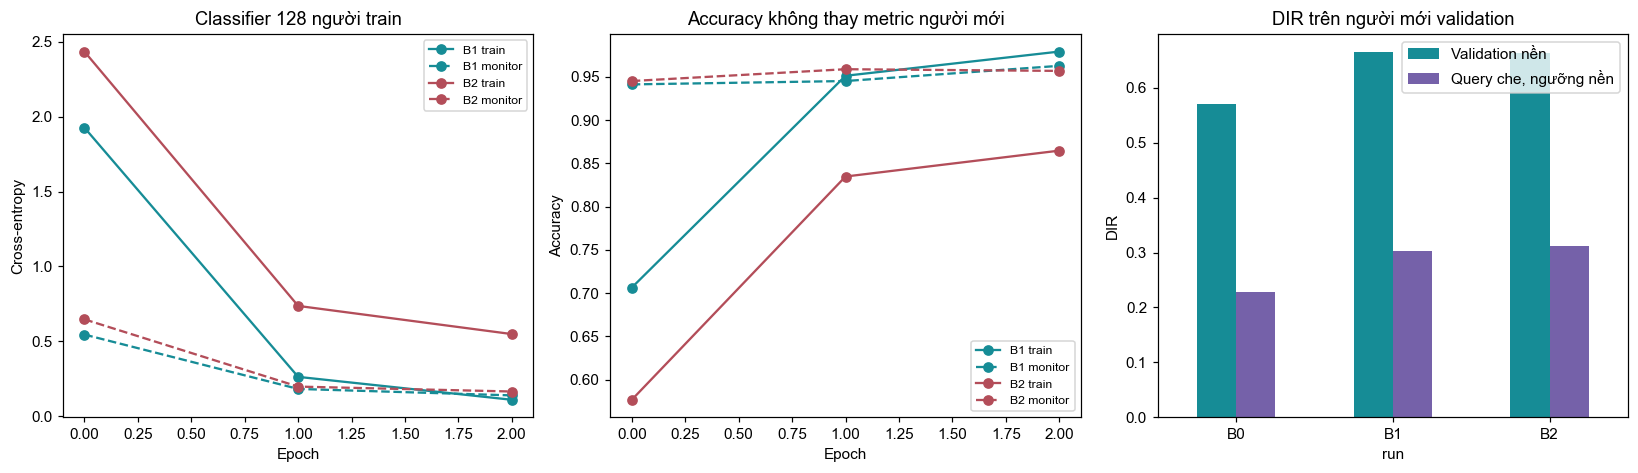

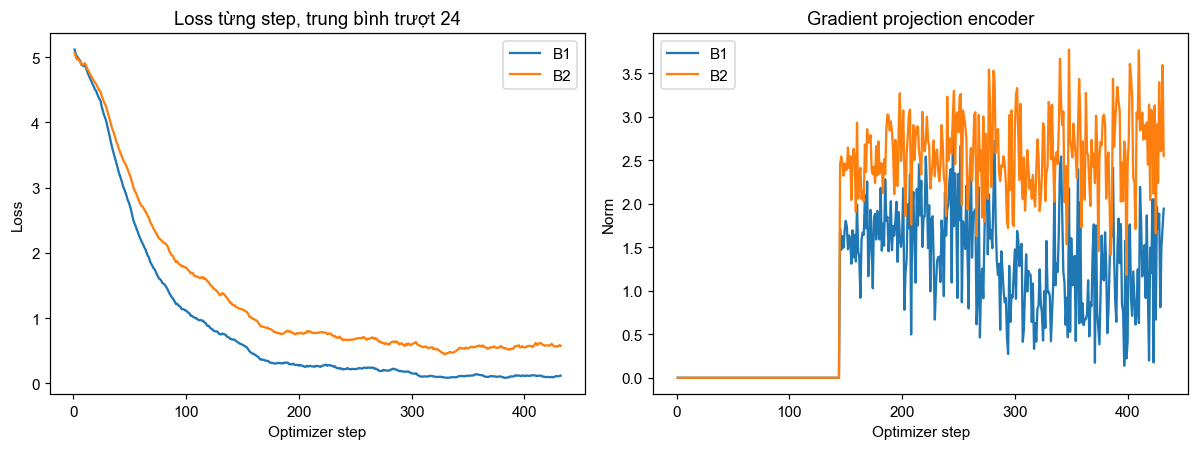

In [11]:
epochs=pd.DataFrame(EPOCH_LOG);steps_frame=pd.DataFrame(STEP_LOG)
fig,axes=plt.subplots(1,3,figsize=(15,4.4))
for branch,color in [('B1','#168C96'),('B2','#B34D59')]:
    f=epochs[epochs.branch.eq(branch)]
    axes[0].plot(f.epoch,f.train_loss,'o-',color=color,label=branch+' train')
    axes[0].plot(f.epoch,f.monitor_loss,'o--',color=color,label=branch+' monitor')
    axes[1].plot(f.epoch,f.train_accuracy,'o-',color=color,label=branch+' train')
    axes[1].plot(f.epoch,f.monitor_accuracy,'o--',color=color,label=branch+' monitor')
comparison.set_index('run')[['DIR','occluded_DIR']].rename(columns={'DIR':'Validation nền','occluded_DIR':'Query che, ngưỡng nền'}).plot.bar(ax=axes[2],rot=0,color=['#168C96','#7561A9'])
axes[0].set(title='Classifier 128 người train',xlabel='Epoch',ylabel='Cross-entropy');axes[0].legend(fontsize=8)
axes[1].set(title='Accuracy không thay metric người mới',xlabel='Epoch',ylabel='Accuracy');axes[1].legend(fontsize=8)
axes[2].set(title='DIR trên người mới validation',ylabel='DIR');fig.tight_layout();finish(fig,'10_training_and_validation')

fig,axes=plt.subplots(1,2,figsize=(11,4.2))
for branch,g in steps_frame.groupby('branch'):
    axes[0].plot(g.step,g.loss.rolling(24,min_periods=1).mean(),label=branch)
    axes[1].plot(g.step,g.encoder_projection_grad_norm,label=branch)
axes[0].set(title='Loss từng step, trung bình trượt 24',xlabel='Optimizer step',ylabel='Loss')
axes[1].set(title='Gradient projection encoder',xlabel='Optimizer step',ylabel='Norm');axes[0].legend();axes[1].legend()
fig.tight_layout();finish(fig,'10_loss_and_encoder_gradient')

## 10. Chi phí thực và dự tính full train

Pilot dùng 128/1.600 danh tính. Dự tính full epoch dựa trên số steps và median step đo thật, cộng validation riêng. Đây là dự tính cho **cùng chính sách mở lớp/cache/batch**, không dùng để hứa thời gian nếu mở toàn encoder hoặc thay phần cứng.

Không tự chạy full train sau pilot. Báo cả dữ liệu augmentation, lựa chọn checkpoint, tài nguyên và giới hạn để người phụ trách chạy cùng cấu hình; mọi run sau có config/run_id riêng.

In [12]:
full_train_images=int((pd.read_csv(ROOT/'ban_giao_nhom/protocol/notebook_outputs/tables/05_image_roles_draft.csv',usecols=['role']).role=='train').sum())
full_steps=math.ceil(full_train_images/CFG['batch_size']);resource_estimates=[]
for stage,g in steps_frame.groupby('stage'):
    median=float(g.step_seconds.median())
    resource_estimates.append({'stage':stage,'median_step_seconds':median,'full_train_images':full_train_images,
       'full_steps_per_epoch':full_steps,'estimated_minutes_per_full_epoch':median*full_steps/60,
       'assumption':'same_partial_encoder_policy_cached_uint8_batch32; excludes_validation_checkpoint_IO'})
save(pd.DataFrame(resource_estimates),'11_full_epoch_time_estimates')
display(pd.DataFrame(resource_estimates))
completed_epochs=epochs.groupby('branch').size().to_dict();completed_steps=steps_frame.groupby('branch').size().to_dict()
assert completed_epochs=={'B1':3,'B2':3} and completed_steps['B1']==completed_steps['B2']==432
assert not steps_frame[steps_frame.branch.eq('B1')].masked_images.any()
for r in CHECKPOINTS:assert sha(ROOT/r['path'])==r['sha256']
assert sha(CONTRACT)==INPUT_HASH['contract']
assert sha(ROOT/'ban_giao_nhom/protocol/notebook_outputs/tables/05_image_roles_draft.csv')==INPUT_HASH['roles']
for r in data.sample(n=64,random_state=SEED).itertuples():assert sha(ROOT/r.path)==r.sha256
summary={'checks':'PASS','scope':'pilot_128_train_identities_not_final_full_training','train_identities':len(labels),
    'train_images':len(T),'monitor_images':len(M),'validation_images':len(V),'validation_occluded_queries':len(VS),
    'epochs_per_branch':completed_epochs,'optimizer_steps_per_branch':completed_steps,
    'same_initialization':INIT_HASHES['B1']==INIT_HASHES['B2'],'same_image_order':ORDERS['B1']==ORDERS['B2'],
    'raw_images_hashed_now':len(data),'pixel_cache_mode':PIXEL_MODE,'training_mode':'computed_now',
    'frozen_and_BN_checks':'PASS_each_epoch','gradient_checks':'PASS_every_finetune_batch',
    'checkpoint_reload_resume':'PASS','score_roundtrip':'PASS','best_encoder_files':ENCODER_FILES,
    'best_epochs':{b:BEST[b]['epoch'] for b in BEST},'best_metrics':{b:BEST[b]['metrics'] for b in BEST},
    'B0_reference':BASELINE,'full_training_completed':False,'test_used':False,'external_used':False,
    'raw_modified':False,'contract_sha256':INPUT_HASH['contract'],'initial_state_sha256':INITIAL_SHA,
    'notebook_source_sha256':SOURCE_SHA,'environment':ENV,'train_and_validation_seconds':TRAIN_SECONDS,
    'executed_at_utc':datetime.now(timezone.utc).isoformat(),'elapsed_seconds':time.perf_counter()-START}
jwrite(summary,'execution_summary.json')
save(pd.DataFrame([{'path':p.relative_to(OUT).as_posix(),'sha256':sha(p),'bytes':p.stat().st_size}
                  for p in sorted(OUT.rglob('*')) if p.is_file() and 'cache' not in p.parts and p.name!='12_artifact_hashes.csv']),
     '12_artifact_hashes')
b1=comparison.set_index('run').loc['B1'];b2=comparison.set_index('run').loc['B2']
display(Markdown(f"""## 11. Kết luận pilot

- Hai nhánh đều **{completed_steps['B1']} optimizer steps / 3 epoch**, cùng initialization và image order. Encoder có gradient thật ở hai epoch fine-tune; warm-up chỉ học classifier.
- **{vn(len(data))} ảnh nguồn** khớp bytes; không dùng test/ROF/MFR2. Tensor chuẩn hóa một lần; cache pixel ở chế độ `{PIXEL_MODE}`, train ở chế độ `computed_now`.
- DIR validation nền ở checkpoint được chọn: **B0 {100*BASELINE['DIR']:.2f}%**, **B1 {100*b1.DIR:.2f}%**, **B2 {100*b2.DIR:.2f}%**, mỗi model FPIR nền ≤5% bằng threshold riêng.
- Query che dùng threshold nền: **B0 {100*BASELINE['occluded_DIR']:.2f}%**, **B1 {100*b1.occluded_DIR:.2f}%**, **B2 {100*b2.occluded_DIR:.2f}%**; xem FPIR tương ứng trong bảng, không coi chúng tự động bằng 5%.
- Checkpoint encoder và resume đã nạp/kiểm được. Chưa hoàn thành full train trên 1.600 identity; một seed/128 người chưa chứng minh ưu thế của augmentation hoặc chất lượng ảnh thật.

**Bước tiếp theo:** dùng thời gian/VRAM và log này để chốt ngân sách full B1/B2, giữ cùng protocol; trước test phải khóa checkpoint, preprocessing, gallery/query và threshold. Kết quả không cải thiện vẫn được giữ, không sửa test để cứu mô hình.
"""))

,stage,median_step_seconds,full_train_images,full_steps_per_epoch,estimated_minutes_per_full_epoch,assumption
0,fine,0.031389,57600,1800,0.941666,same_partial_encoder_policy_cached_uint8_batch...
1,warmup,0.027547,57600,1800,0.826403,same_partial_encoder_policy_cached_uint8_batch...


## 11. Kết luận pilot

- Hai nhánh đều **432 optimizer steps / 3 epoch**, cùng initialization và image order. Encoder có gradient thật ở hai epoch fine-tune; warm-up chỉ học classifier.
- **13.120 ảnh nguồn** khớp bytes; không dùng test/ROF/MFR2. Tensor chuẩn hóa một lần; cache pixel ở chế độ `computed_now`, train ở chế độ `computed_now`.
- DIR validation nền ở checkpoint được chọn: **B0 57.16%**, **B1 66.49%**, **B2 66.35%**, mỗi model FPIR nền ≤5% bằng threshold riêng.
- Query che dùng threshold nền: **B0 22.73%**, **B1 30.30%**, **B2 31.27%**; xem FPIR tương ứng trong bảng, không coi chúng tự động bằng 5%.
- Checkpoint encoder và resume đã nạp/kiểm được. Chưa hoàn thành full train trên 1.600 identity; một seed/128 người chưa chứng minh ưu thế của augmentation hoặc chất lượng ảnh thật.

**Bước tiếp theo:** dùng thời gian/VRAM và log này để chốt ngân sách full B1/B2, giữ cùng protocol; trước test phải khóa checkpoint, preprocessing, gallery/query và threshold. Kết quả không cải thiện vẫn được giữ, không sửa test để cứu mô hình.


## 12. Chạy lại và bàn giao

Chạy augmentation Notebook trước, sau đó notebook này từ kernel mới. `checkpoints/*_best_encoder.pt` dùng evaluator embedding; `*_resume.pt` kèm optimizer/head/RNG cho tiếp tục train. Không dùng classifier 128 lớp để nhận diện người validation/webcam mới.

Chạy lại notebook luôn tạo lượt train mới theo seed/cấu hình, các file trong bản pilot này được ghi lại; nếu cần giữ nhiều run thì sao chép thư mục run hoặc tăng version trước chạy. Cache chỉ tăng tốc ảnh nền, không thay lượt train.

Nguồn: [facenet-pytorch fine-tune](https://github.com/timesler/facenet-pytorch/blob/master/examples/finetune.ipynb), [PyTorch 2.2 reproducibility](https://docs.pytorch.org/docs/2.2/notes/randomness.html); mã thư viện cài thực tế và protocol bước 5 là hợp đồng được kiểm trong code. Checkpoint/CI là kết quả pilot, không phải benchmark cuối.